In [33]:
import pandas as pd

df = pd.read_csv('outputs/pupils_pupils.csv')
df

,timestamp [ns],xL,yL,diameter_L,confidence_L,xR,yR,diameter_R,confidence_R
0,1776686284555671971,119.922,119.697,18.725,0.809,66.458,108.135,19.691,0.804
1,1776686284560671971,119.922,119.697,18.725,0.830,66.458,108.135,19.691,0.811
2,1776686284565672971,119.840,118.660,20.183,0.957,66.458,108.135,19.691,0.811
3,1776686284570680971,121.000,118.000,NaN,NaN,66.630,107.504,20.536,0.811
4,1776686284575672971,121.000,118.000,NaN,NaN,66.371,108.126,20.023,0.833
...,...,...,...,...,...,...,...,...,...
20214,1776686386379293971,127.000,130.000,NaN,NaN,91.000,118.000,NaN,NaN
20215,1776686386384293971,127.000,130.000,NaN,NaN,91.000,118.000,NaN,NaN
20216,1776686386389309971,127.000,130.000,NaN,NaN,91.000,118.000,NaN,NaN
20217,1776686386394296971,127.000,130.000,NaN,NaN,91.000,118.000,NaN,NaN


In [34]:
# Downsample to 30 fps (6x downsampling) while prioritizing rows without NaN and high confidence
target_fps = 30
current_fps = 200
downsample_factor = current_fps // target_fps

# Create a mask for rows without NaN in key columns
valid_mask = df[['xL', 'yL', 'diameter_L', 'xR', 'yR', 'diameter_R']].notna().all(axis=1)

# Calculate average confidence for each row
df['avg_confidence'] = (df['confidence_L'] + df['confidence_R']) / 2

# Downsample with preference for valid rows and high confidence
df_downsampled_optimized = []
for i in range(0, len(df), downsample_factor):
    chunk = df.iloc[i:i+downsample_factor]
    
    # Prefer valid rows with high confidence
    valid_chunk = chunk[valid_mask.iloc[i:i+downsample_factor]]
    if len(valid_chunk) > 0:
        best_row = valid_chunk.loc[valid_chunk['avg_confidence'].idxmax()]
    else:
        best_row = chunk.iloc[0]
    
    df_downsampled_optimized.append(best_row)

df_downsampled_optimized = pd.DataFrame(df_downsampled_optimized).reset_index(drop=True)
df_downsampled_optimized

,timestamp [ns],xL,yL,diameter_L,confidence_L,xR,yR,diameter_R,confidence_R,avg_confidence
0,1.776686e+18,119.840,118.660,20.183,0.957,66.458,108.135,19.691,0.811,0.8840
1,1.776686e+18,119.176,117.777,22.244,0.887,66.242,107.435,20.857,0.831,0.8590
2,1.776686e+18,116.966,117.864,23.859,0.679,66.485,109.283,18.663,0.933,0.8060
3,1.776686e+18,116.879,117.504,24.252,0.740,66.193,108.925,19.308,0.860,0.8000
4,1.776686e+18,119.585,120.333,20.108,0.921,66.414,108.995,19.523,0.895,0.9080
...,...,...,...,...,...,...,...,...,...,...
3365,1.776686e+18,124.311,126.205,23.448,0.764,87.387,114.462,26.346,0.979,0.8715
3366,1.776686e+18,123.346,130.137,19.067,0.815,88.163,116.589,24.840,1.000,0.9075
3367,1.776686e+18,122.750,129.924,18.727,0.811,86.976,114.257,27.887,0.980,0.8955
3368,1.776686e+18,124.000,130.000,NaN,NaN,88.362,117.074,24.167,0.980,NaN


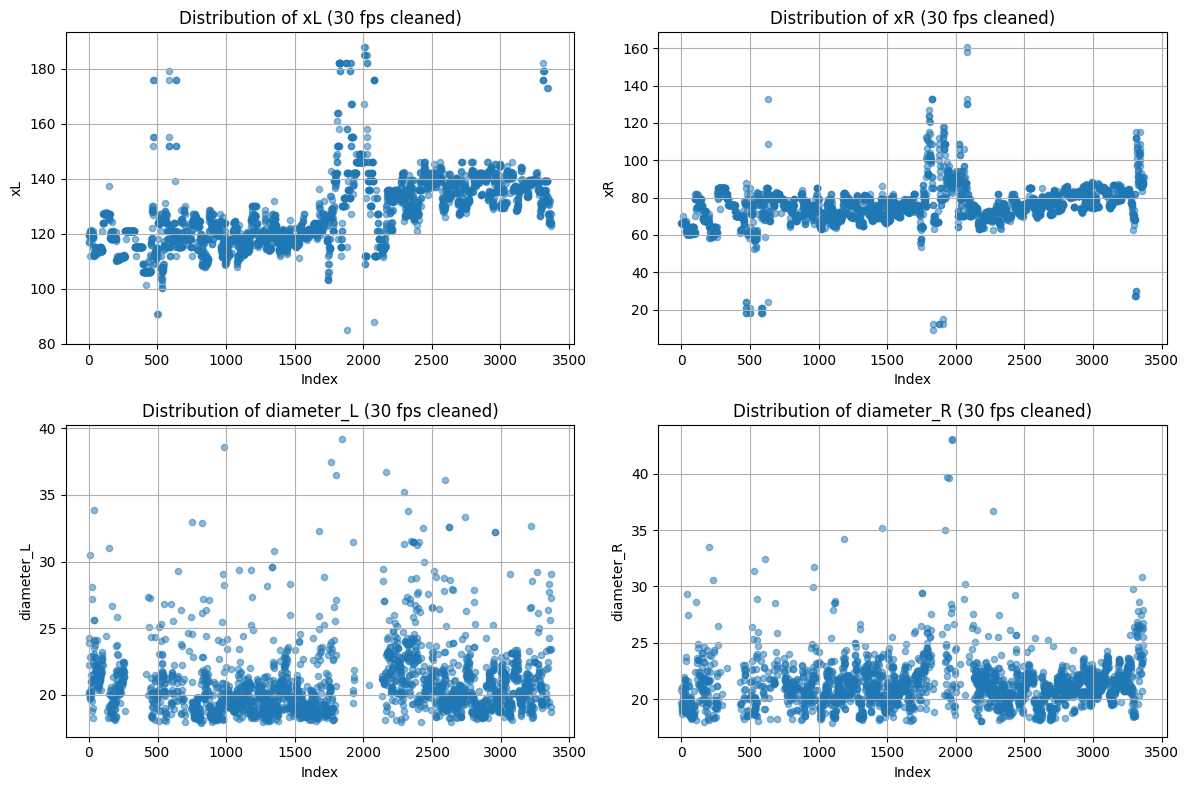

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Distribution of xL
axes[0, 0].scatter(range(len(df_downsampled_optimized)), df_downsampled_optimized['xL'], alpha=0.5, s=20)
axes[0, 0].set_xlabel('Index')
axes[0, 0].set_ylabel('xL')
axes[0, 0].set_title('Distribution of xL (30 fps cleaned)')
axes[0, 0].grid(True)

# Distribution of xR
axes[0, 1].scatter(range(len(df_downsampled_optimized)), df_downsampled_optimized['xR'], alpha=0.5, s=20)
axes[0, 1].set_xlabel('Index')
axes[0, 1].set_ylabel('xR')
axes[0, 1].set_title('Distribution of xR (30 fps cleaned)')
axes[0, 1].grid(True)

# Distribution of diameter_L
axes[1, 0].scatter(range(len(df_downsampled_optimized)), df_downsampled_optimized['diameter_L'], alpha=0.5, s=20)
axes[1, 0].set_xlabel('Index')
axes[1, 0].set_ylabel('diameter_L')
axes[1, 0].set_title('Distribution of diameter_L (30 fps cleaned)')
axes[1, 0].grid(True)

# Distribution of diameter_R
axes[1, 1].scatter(range(len(df_downsampled_optimized)), df_downsampled_optimized['diameter_R'], alpha=0.5, s=20)
axes[1, 1].set_xlabel('Index')
axes[1, 1].set_ylabel('diameter_R')
axes[1, 1].set_title('Distribution of diameter_R (30 fps cleaned)')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

In [36]:
# Get minimum confidence values
min_confidence_L = df_downsampled_optimized['confidence_L'].min()
min_confidence_R = df_downsampled_optimized['confidence_R'].min()

print(f"Min confidence_L: {min_confidence_L}")
print(f"Min confidence_R: {min_confidence_R}")


Min confidence_L: 0.312
Min confidence_R: 0.254


In [24]:
import cv2
import numpy as np

video_path = '/home/homeoffice/Desktop/MasterArbeit/Gaze_estimation/data/2026-04-20_13-58-02-dffaeb67/Neon Sensor Module v1 ps1.mp4'
output_path = 'output_with_pupil_fixed_3.mp4'

target_fps = 30
current_fps = 200
downsample_factor = current_fps // target_fps  # = 6

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
half_width = width // 2

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

frame_idx = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break

    # Каждые 6 кадров 200fps -> 1 строка 30fps данных
    data_idx = frame_idx // downsample_factor

    if data_idx < len(df_downsampled_optimized):
        row = df_downsampled_optimized.iloc[data_idx]

        if not np.isnan(row['xL']) and not np.isnan(row['yL']):
            cv2.circle(frame, (int(row['xL']), int(row['yL'])), 5, (0, 255, 0), 2)

        if not np.isnan(row['xR']) and not np.isnan(row['yR']):
            cv2.circle(frame, (int(row['xR']) + half_width, int(row['yR'])), 5, (0, 0, 255), 2)

    out.write(frame)
    frame_idx += 1  # +1, не +30!

cap.release()
out.release()
print(f"Готово: {output_path}")


Готово: output_with_pupil_fixed_3.mp4


In [37]:
df_downsampled_optimized.to_csv('30_fps_data.csv', index=False)